In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

# Time series: Q1

## Parameters

In [2]:
rho = 0.95
sigma = 0.25

T=20
t=range(1,T+1)
x=1


## i. Plot the conditional mean

In [3]:
E_x = []

for i in t:
    E_x.append( x*(rho**(i-1)) )


Text(0.5, 1.0, 'Evolution of the conditional mean')

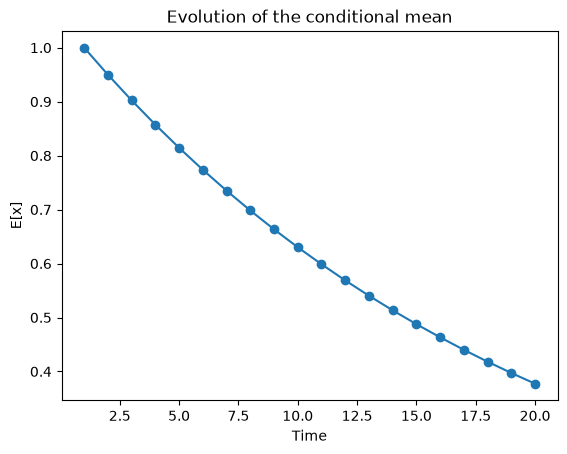

In [4]:
plt.plot(t, E_x, marker='o')
plt.ylabel('E[x]')
plt.xlabel('Time')
plt.title('Evolution of the conditional mean')

## ii. Add +/- one conditional std

In [5]:
t

range(1, 21)

In [6]:
VAR_x = []

for j in t:
    VAR_x.append(sigma**2 * (1 - rho**(2*(j-1))) / (1 - rho**2))

In [7]:
#conversion needed
E_x = np.array(E_x)
VAR_x = np.array(VAR_x)

E_x_plus_VAR = E_x + np.sqrt(VAR_x)
E_x_minus_VAR = E_x - np.sqrt(VAR_x)

Text(0.5, 1.0, 'Evolution of the conditional mean ±1 std')

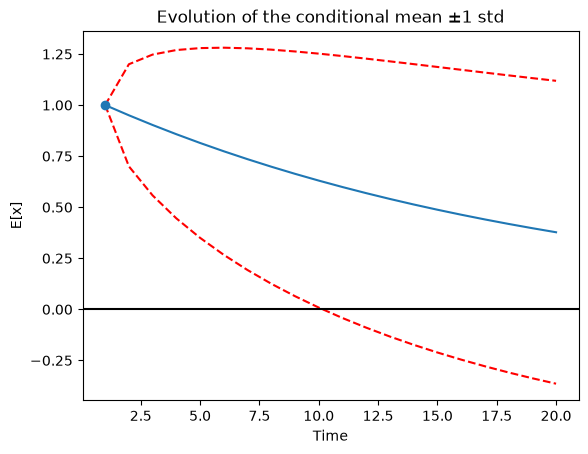

In [8]:
plt.plot(t, E_x)
plt.plot(t, E_x_plus_VAR, color='r', linestyle='dashed')
plt.plot(t, E_x_minus_VAR, color='r', linestyle='dashed')
plt.scatter(1, 1, zorder=5)
plt.axhline(y=0, color='black')
plt.ylabel('E[x]')
plt.xlabel('Time')
plt.title('Evolution of the conditional mean ±1 std')

Interpretation:
- Best guess is long term drift.
- visible if we change t=50, 100, ...  (add those graphs)
- Mean reverting process

- Incertitude grows with time = Forecast uncertainty builds up with the horizon.
-> long-run forecasts converge to the unconditional mean.



## iii. Chebychev inequality vs normality assumption

### Normality assumption

Text(0.5, 1.0, 'Prediction cone under normality (90%)')

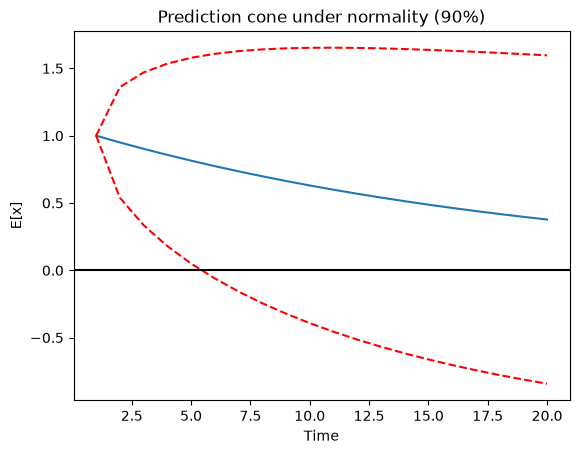

In [9]:
normal_band_90_plus = E_x + 1.645 * np.sqrt(VAR_x)
normal_band_90_minus = E_x - 1.645 * np.sqrt(VAR_x)
plt.plot(t, E_x)
plt.plot(t, normal_band_90_plus, color='r', linestyle='dashed')
plt.plot(t, normal_band_90_minus, color='r', linestyle='dashed')
plt.axhline(y=0, color='black')
plt.ylabel('E[x]')
plt.xlabel('Time')
plt.title('Prediction cone under normality (90%)')

Text(0.5, 1.0, 'Prediction cone under normality (95%)')

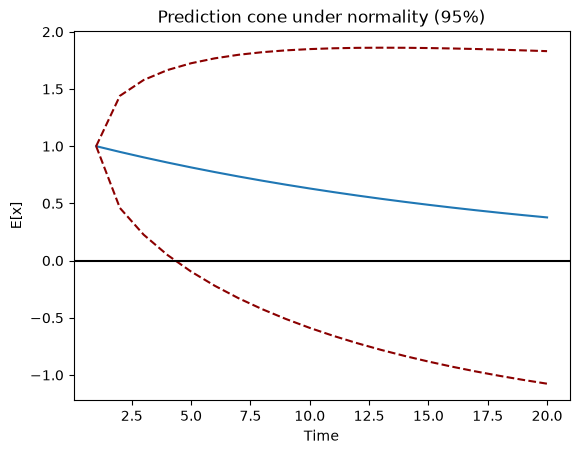

In [10]:
normal_band_95_plus = E_x + 1.96 * np.sqrt(VAR_x)
normal_band_95_minus = E_x - 1.96 * np.sqrt(VAR_x)
plt.plot(t, E_x)
plt.plot(t, normal_band_95_plus, color='darkred', linestyle='dashed')
plt.plot(t, normal_band_95_minus, color='darkred', linestyle='dashed')
plt.axhline(y=0, color='black')
plt.ylabel('E[x]')
plt.xlabel('Time')
plt.title('Prediction cone under normality (95%)')

Text(0.5, 1.0, 'Prediction cones comparison under normality')

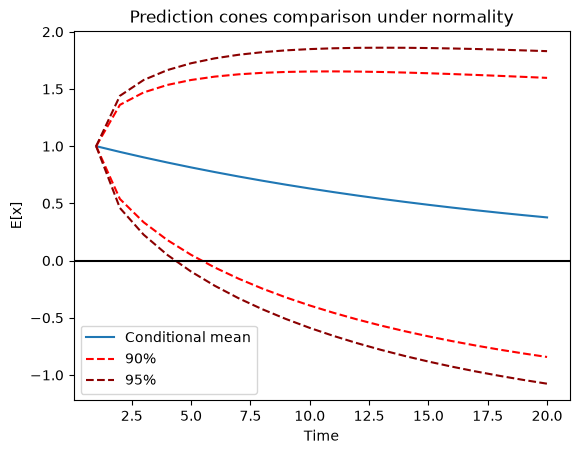

In [11]:
plt.plot(t, E_x)
plt.plot(t, normal_band_90_plus, color='r', linestyle='dashed')
plt.plot(t, normal_band_95_plus, color='darkred', linestyle='dashed')
plt.plot(t, normal_band_90_minus, color='r', linestyle='dashed')
plt.plot(t, normal_band_95_minus, color='darkred', linestyle='dashed')
plt.axhline(y=0, color='black')
plt.ylabel('E[x]')
plt.xlabel('Time')
plt.legend(['Conditional mean','90%', '95%'])
plt.title('Prediction cones comparison under normality')

### Chebychev Inequality

Text(0.5, 1.0, 'Prediction cone under Chebychev inequality (90%)')

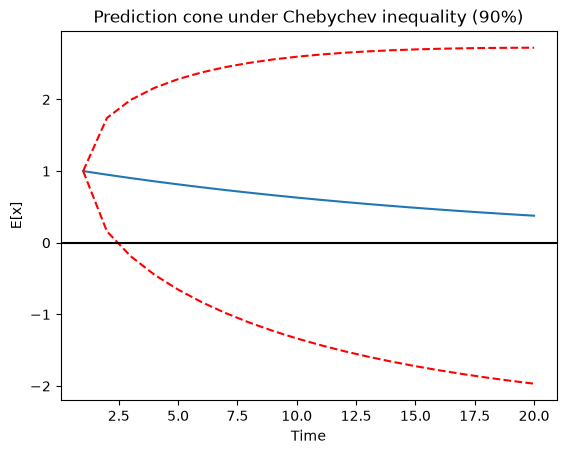

In [12]:
k_90=np.sqrt(10)
chebychev_band_90_plus = E_x + k_90 * np.sqrt(VAR_x)
chebychev_band_90_minus = E_x - k_90 * np.sqrt(VAR_x)
plt.plot(t, E_x)
plt.plot(t, chebychev_band_90_plus, color='r', linestyle='dashed')
plt.plot(t, chebychev_band_90_minus, color='r', linestyle='dashed')
plt.axhline(y=0, color='black')
plt.ylabel('E[x]')
plt.xlabel('Time')
plt.title('Prediction cone under Chebychev inequality (90%)')

Text(0.5, 1.0, 'Prediction cone under Chebychev inequality (95%)')

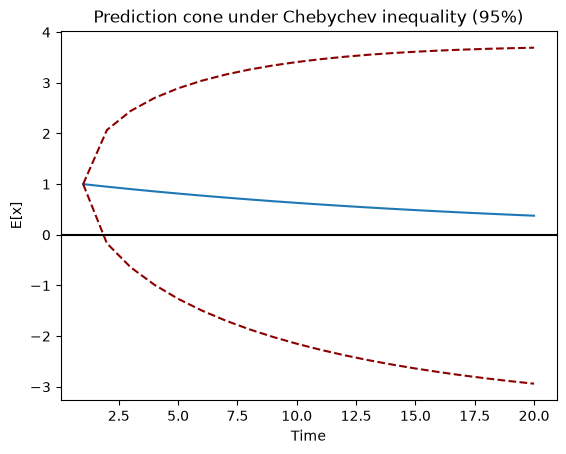

In [13]:
k_95=np.sqrt(20)
chebychev_band_95_plus = E_x + k_95 * np.sqrt(VAR_x)
chebychev_band_95_minus = E_x - k_95 * np.sqrt(VAR_x)
plt.plot(t, E_x)
plt.plot(t, chebychev_band_95_plus, color='darkred', linestyle='dashed')
plt.plot(t, chebychev_band_95_minus, color='darkred', linestyle='dashed')
plt.axhline(y=0, color='black')
plt.ylabel('E[x]')
plt.xlabel('Time')
plt.title('Prediction cone under Chebychev inequality (95%)')

Text(0.5, 1.0, 'Prediction cones comparison under Chebychev')

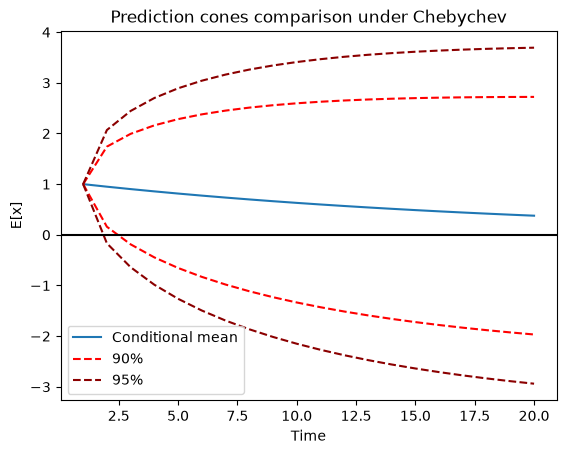

In [14]:
plt.plot(t, E_x)
plt.plot(t, chebychev_band_90_plus, color='r', linestyle='dashed')
plt.plot(t, chebychev_band_95_plus, color='darkred', linestyle='dashed')
plt.plot(t, chebychev_band_90_minus, color='r', linestyle='dashed')
plt.plot(t, chebychev_band_95_minus, color='darkred', linestyle='dashed')
plt.axhline(y=0, color='black')
plt.ylabel('E[x]')
plt.xlabel('Time')
plt.legend(['Conditional mean','90%', '95%'])
plt.title('Prediction cones comparison under Chebychev')

### Comparison Normality vs Chebychev

Text(0.5, 1.0, 'Prediction cones comparison: Normality vs Chebychev (90%)')

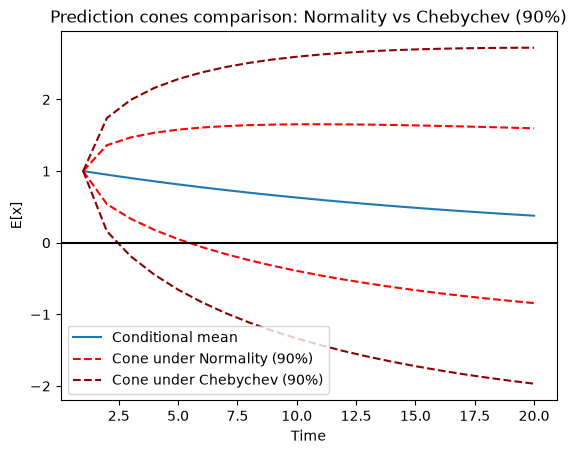

In [15]:
plt.plot(t, E_x)
plt.plot(t, normal_band_90_plus, color='r', linestyle='dashed')
plt.plot(t, chebychev_band_90_plus, color='darkred', linestyle='dashed')
plt.plot(t, normal_band_90_minus, color='r', linestyle='dashed')
plt.plot(t, chebychev_band_90_minus, color='darkred', linestyle='dashed')
plt.axhline(y=0, color='black')
plt.ylabel('E[x]')
plt.xlabel('Time')
plt.legend(['Conditional mean','Cone under Normality (90%)', 'Cone under Chebychev (90%)'])
plt.title('Prediction cones comparison: Normality vs Chebychev (90%)')

Text(0.5, 1.0, 'Prediction cones comparison: Normality vs Chebychev (95%)')

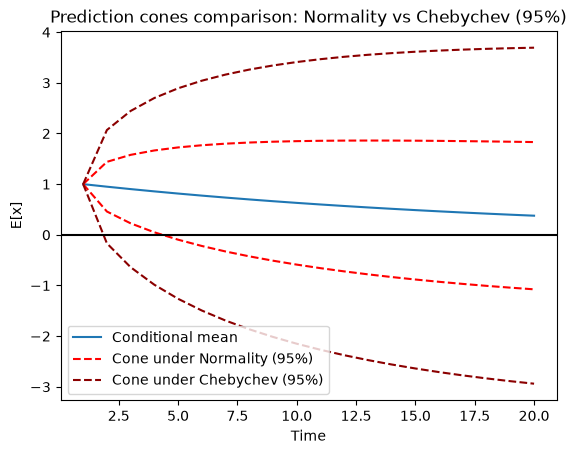

In [16]:
plt.plot(t, E_x)
plt.plot(t, normal_band_95_plus, color='r', linestyle='dashed')
plt.plot(t, chebychev_band_95_plus, color='darkred', linestyle='dashed')
plt.plot(t, normal_band_95_minus, color='r', linestyle='dashed')
plt.plot(t, chebychev_band_95_minus, color='darkred', linestyle='dashed')
plt.axhline(y=0, color='black')
plt.ylabel('E[x]')
plt.xlabel('Time')
plt.legend(['Conditional mean','Cone under Normality (95%)', 'Cone under Chebychev (95%)'])
plt.title('Prediction cones comparison: Normality vs Chebychev (95%)')

## iv. Path simulation


In [17]:
T=20
sigma = 0.25
rho = 0.95


In [18]:
eps = []
for s in range(20):
    eps.append(np.random.normal(0, sigma, size=T))


In [19]:
for d in range(20):
    eps[d][0] = 0

In [20]:
paths = []

for e in range(20):
    x = np.empty(T)
    x[0] = 1
    for t in range(0, T-1):        # t = 0, 1, ..., 18
        x[t+1] = rho * x[t] + eps[e][t+1]
    paths.append(x.copy())


In [21]:
paths = np.array(paths).T

Text(0.5, 1.0, 'Simulation of 20 AR(1) paths')

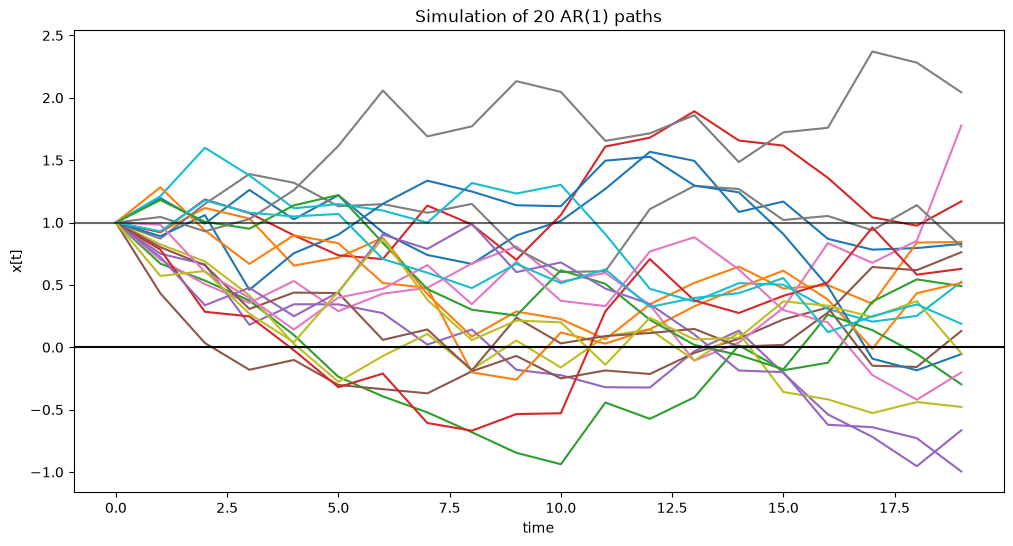

In [22]:
plt.figure(figsize=(12, 6))
plt.plot(paths)  # transpose: (T, 20) → 20 colonnes = 20 séries
plt.axhline(y=0, color='black')
plt.axhline(y=1, color='black', alpha=0.6)
plt.ylabel('x[t]')
plt.xlabel('time')
plt.title('Simulation of 20 AR(1) paths')

Text(0.5, 1.0, 'Simulation of 20 AR(1) paths with 90% theoretical prediction cones')

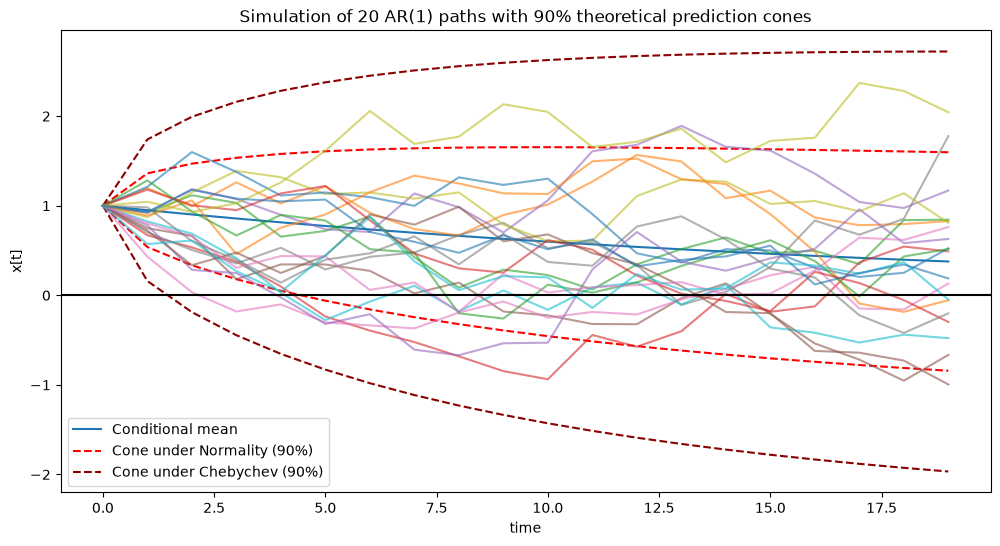

In [23]:
plt.figure(figsize=(12, 6))
plt.plot(E_x)
plt.plot(normal_band_90_plus, color='r', linestyle='dashed')
plt.plot(chebychev_band_90_plus, color='darkred', linestyle='dashed')
plt.plot(normal_band_90_minus, color='r', linestyle='dashed')
plt.plot(chebychev_band_90_minus, color='darkred', linestyle='dashed')
plt.plot(paths, alpha = 0.6)
plt.legend(['Conditional mean','Cone under Normality (90%)', 'Cone under Chebychev (90%)'])
plt.axhline(y=0, color='black')
plt.ylabel('x[t]')
plt.xlabel('time')
plt.title('Simulation of 20 AR(1) paths with 90% theoretical prediction cones')

Text(0.5, 1.0, 'Simulation of 20 AR(1) paths with 95% theoretical prediction cones')

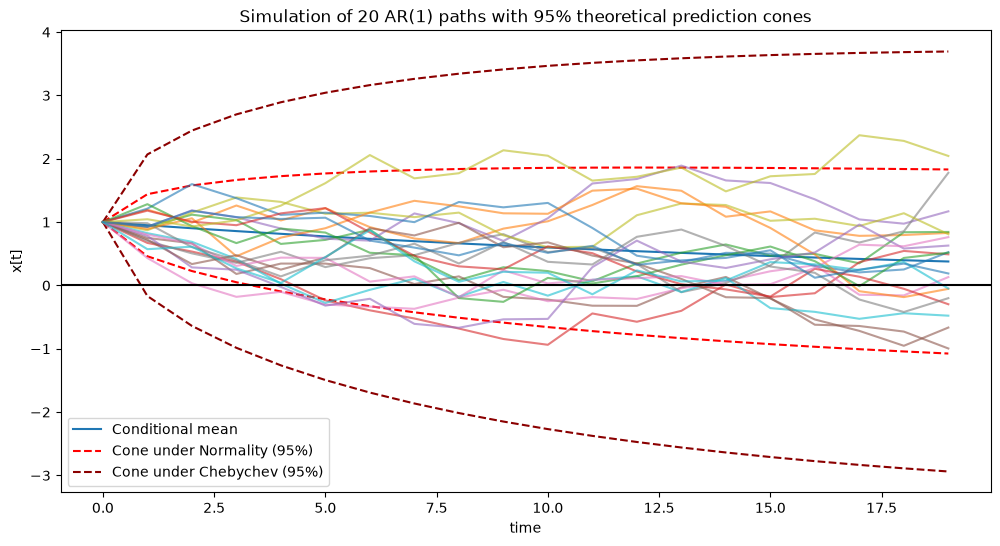

In [24]:
plt.figure(figsize=(12, 6))
plt.plot(E_x)
plt.plot(normal_band_95_plus, color='r', linestyle='dashed')
plt.plot(chebychev_band_95_plus, color='darkred', linestyle='dashed')
plt.plot(normal_band_95_minus, color='r', linestyle='dashed')
plt.plot(chebychev_band_95_minus, color='darkred', linestyle='dashed')
plt.plot(paths, alpha = 0.6)
plt.legend(['Conditional mean','Cone under Normality (95%)', 'Cone under Chebychev (95%)'])
plt.axhline(y=0, color='black')
plt.ylabel('x[t]')
plt.xlabel('time')
plt.title('Simulation of 20 AR(1) paths with 95% theoretical prediction cones')

# Time series: Q2

## h) i. B.

In [25]:
T=5

In [26]:
def MA(T, delta, color):
    r = [0]*T
    e = [0]*T
    e[1] = 1

    for t in range(1,T):
        r[t] = e[t] + delta*e[t-1]

    p = np.cumsum(r)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))

    ax1.plot(r, color=color, marker='o')
    ax1.set_xlabel('t')
    ax1.set_ylabel('r_t')
    ax1.set_title(f'Impulse-response function with  δ={delta}')

    ax2.plot(p, color=color, marker='o')
    ax2.set_xlabel('t')
    ax2.set_ylabel('p_t')
    ax2.set_title(f'Cumulative log return function with  δ={delta}')

    print(r)
    print(p)

    return r, p

[0, 1.0, 0.5, 0.0, 0.0]
[0.  1.  1.5 1.5 1.5]


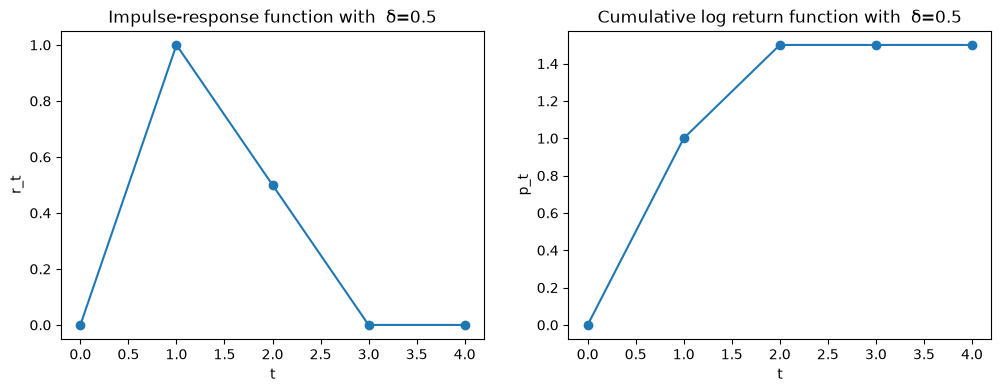

In [27]:
r_momentum, p_momentum = MA(T, delta = 0.5, color = 'C0')

[0, 1, 0, 0, 0]
[0 1 1 1 1]


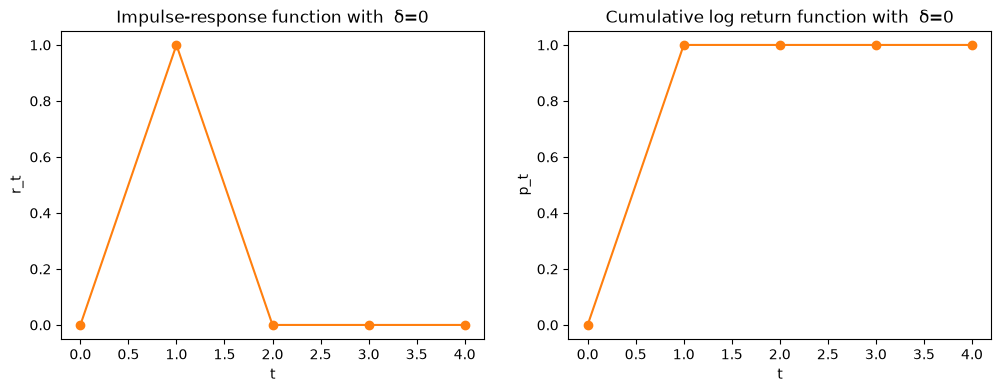

In [28]:
r_iid, p_iid = MA(T, delta = 00, color = 'C1')

[0, 1.0, -0.5, 0.0, 0.0]
[0.  1.  0.5 0.5 0.5]


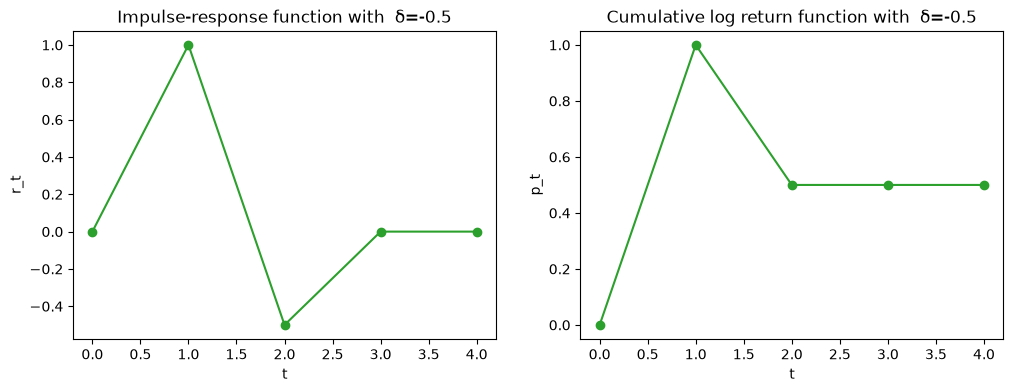

In [29]:
r_mean_rev, p_mean_rev = MA(T, delta = -0.5, color = 'C2')

Text(0.5, 1.0, 'Cumulative log return function (p_t)')

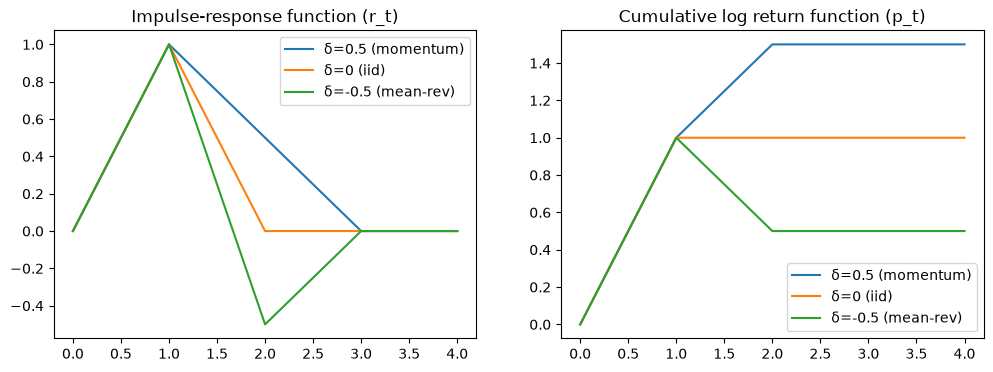

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))

ax1.plot(r_momentum, label='δ=0.5 (momentum)')
ax1.plot(r_iid, label='δ=0 (iid)')
ax1.plot(r_mean_rev, label='δ=-0.5 (mean-rev)')
ax1.legend()
ax1.set_title('Impulse-response function (r_t)')

ax2.plot(p_momentum, label='δ=0.5 (momentum)')
ax2.plot(p_iid, label='δ=0 (iid)')
ax2.plot(p_mean_rev, label='δ=-0.5 (mean-rev)')
ax2.legend()
ax2.set_title('Cumulative log return function (p_t)')

# Stock Market Q3.1

## Part 1)

In [31]:
import yfinance as yf

### 1. Data

In [32]:
tickers = ["VEUSX", "VBLIX"]
#VEUSX - Vanguard European Stock Index Fund
#VBLIX - Vanguard Long-Term Bond Fund
raw = yf.download(tickers, start="2015-01-01", auto_adjust=True)["Close"]

#Prices
prices_m = raw.resample("ME").last().dropna()

#Normalized
prices_norm = prices_m / prices_m.iloc[0] * 100

#Returns
ret_m = prices_m.pct_change().dropna()

[*********************100%***********************]  2 of 2 completed


### 2. normalized price chart

Text(0, 0.5, '%')

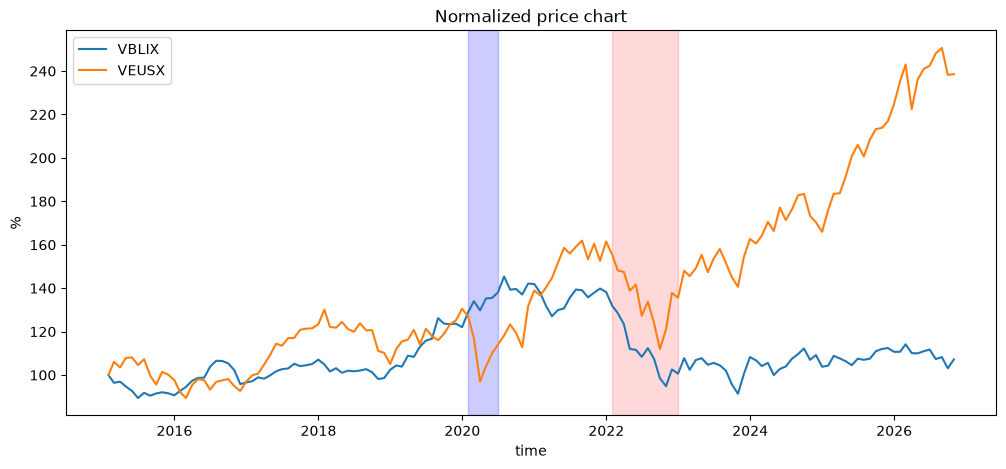

In [33]:
plt.figure(figsize=(12, 5))
plt.plot(prices_norm)
plt.axvspan("2020-02-01", "2020-06-30", color="blue", alpha=0.2, label="COVID-19")
plt.axvspan("2022-02-01", "2022-12-31", color="red", alpha=0.15, label="War in Ukraine")
plt.legend(prices_norm)
plt.title("Normalized price chart")
plt.xlabel("time")
plt.ylabel("%")

### 3. Sample moments

In [34]:
mu  = ret_m.mean()
cov = ret_m.cov()
std = ret_m.std()

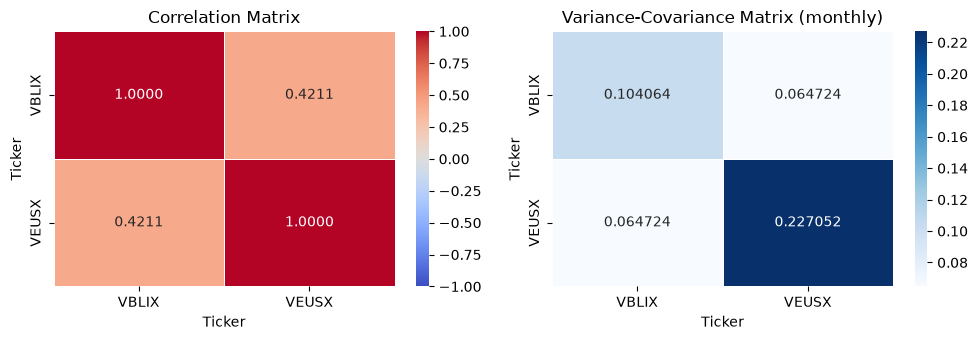

In [35]:
corr = ret_m.corr()
cov_100  = ret_m.cov() * 100  # en % pour lisibilité

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

sns.heatmap(corr, annot=True, fmt=".4f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, ax=axes[0], linewidths=0.5)
axes[0].set_title("Correlation Matrix")

sns.heatmap(cov_100, annot=True, fmt=".6f", cmap="Blues",
            ax=axes[1], linewidths=0.5)
axes[1].set_title("Variance-Covariance Matrix (monthly)")

plt.tight_layout()
plt.savefig("heatmaps.png", dpi=150)
plt.show()

### 4. Efficient frontier

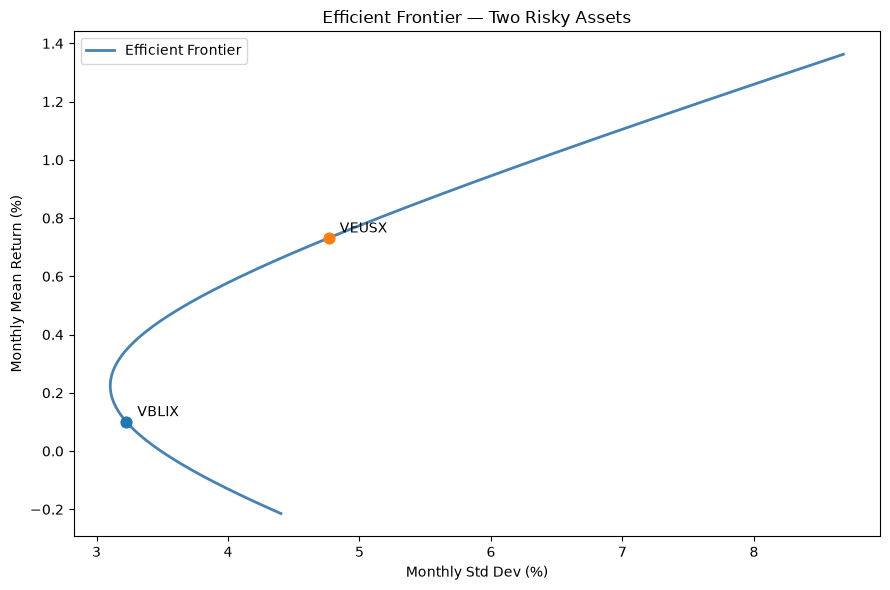

In [36]:
mu  = ret_m.mean().values        # shape (2,)
cov = ret_m.cov().values         # shape (2,2)

# Efficient frontier
weights = np.linspace(-1, 1.5, 500)

port_ret = []
port_std = []

for w in weights:
    wvec      = np.array([w, 1 - w])
    port_ret.append(wvec @ mu)
    port_std.append(np.sqrt(wvec @ cov @ wvec))

port_ret = np.array(port_ret)
port_std = np.array(port_std)

# Plot
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(port_std * 100, port_ret * 100, color="steelblue", lw=2, label="Efficient Frontier")

# Individual assets
for name, m, s in zip(["VBLIX", "VEUSX"], mu, np.sqrt(np.diag(cov))):
    ax.scatter(s * 100, m * 100, zorder=5, s=60)
    ax.annotate(name, (s * 100, m * 100), textcoords="offset points", xytext=(8, 4))

ax.set_xlabel("Monthly Std Dev (%)")
ax.set_ylabel("Monthly Mean Return (%)")
ax.set_title("Efficient Frontier — Two Risky Assets")
ax.legend()
plt.tight_layout()
plt.show()

### 5) Min variance portfolio

In [37]:
# Min var pf
w_min_var = (cov[1,1] - cov[0,1]) / (cov[0,0] + cov[1,1] - 2*cov[0,1])
ret_min_var = np.array([w_min_var, 1-w_min_var]) @ mu
std_min_var = np.sqrt(np.array([w_min_var, 1-w_min_var]) @ cov @ np.array([w_min_var, 1-w_min_var]))
sharpe_min_var = (ret_min_var - 0.00025) / std_min_var

print(f"MV weights  : VBLIX={w_min_var:.4f}, VEUSX={1-w_min_var:.4f}")
print(f"MV mean     : {ret_min_var*100:.4f}%")
print(f"MV std      : {std_min_var*100:.4f}%")
print(f"MV Sharpe  : {sharpe_min_var:.4f}")

#yearly data
ret_min_var_yr = ret_min_var*12
std_min_var_yr = std_min_var*np.sqrt(12)
sharpe_min_var_yr = (ret_min_var_yr - 0.00025*12) / std_min_var_yr

print(f"Yearly MV mean     : {ret_min_var_yr*100:.4f}%")
print(f"Yearly MV std      : {std_min_var_yr*100:.4f}%")
print(f"Yearly MV Sharpe  : {sharpe_min_var_yr:.4f}")


MV weights  : VBLIX=0.8049, VEUSX=0.1951
MV mean     : 0.2239%
MV std      : 3.1047%
MV Sharpe  : 0.0641
Yearly MV mean     : 2.6872%
Yearly MV std      : 10.7549%
Yearly MV Sharpe  : 0.2220


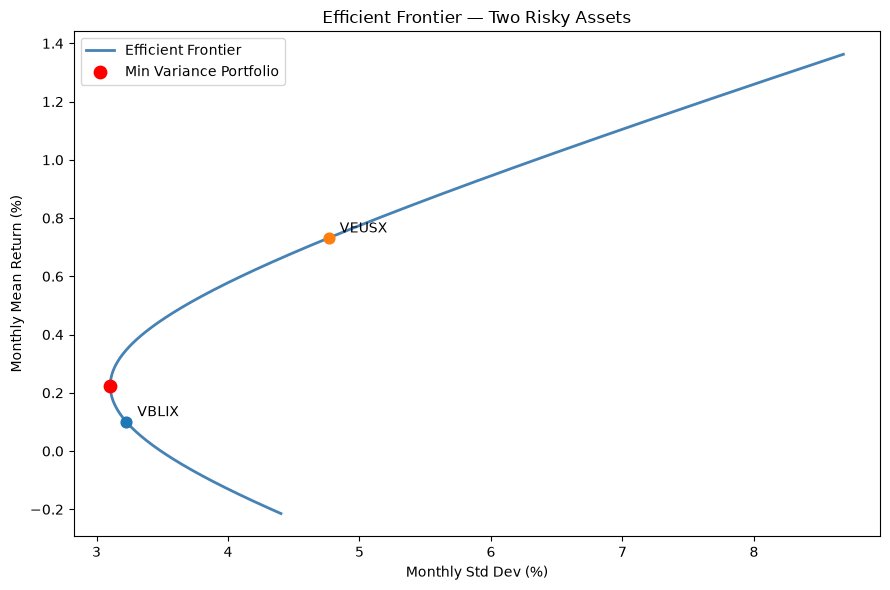

In [38]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(port_std * 100, port_ret * 100, color="steelblue", lw=2, label="Efficient Frontier")
#Min_var
ax.scatter(std_min_var * 100, ret_min_var * 100, color="red", zorder=5, s=80, label="Min Variance Portfolio")

# Individual assets
for name, m, s in zip(["VBLIX", "VEUSX"], mu, np.sqrt(np.diag(cov))):
    ax.scatter(s * 100, m * 100, zorder=5, s=60)
    ax.annotate(name, (s * 100, m * 100), textcoords="offset points", xytext=(8, 4))

ax.set_xlabel("Monthly Std Dev (%)")
ax.set_ylabel("Monthly Mean Return (%)")
ax.set_title("Efficient Frontier — Two Risky Assets")
ax.legend()
plt.tight_layout()
plt.show()

### 6) Max sharpe portfolio (tangency)

In [39]:
from scipy.optimize import minimize


In [40]:
rf = 0.00025

excess_mu = mu - rf

inv_cov   = np.linalg.inv(cov)
ones      = np.ones(len(mu))

w_tan_raw    = inv_cov @ excess_mu
w_tangency   = w_tan_raw / (ones @ w_tan_raw)  # weights sum to 1

ret_tangency  = w_tangency @ mu
std_tangency  = np.sqrt(w_tangency @ cov @ w_tangency)  # ← était w_tan
sharp_tangency = (ret_tangency - rf) / std_tangency      # ← était tan_ret/tan_std

print(f"Tangency weights : VBLIX={w_tangency[0]:.4f}, VEUSX={w_tangency[1]:.4f}")  # ← était w_tan[1]
print(f"Tangency mean    : {ret_tangency*100:.4f}%")
print(f"Tangency std     : {std_tangency*100:.4f}%")
print(f"Sharpe ratio     : {sharp_tangency:.4f}")

# Annualized
ret_tangency_yr   = ret_tangency * 12
std_tangency_yr   = std_tangency * np.sqrt(12)
sharp_tangency_yr = (ret_tangency_yr - rf * 12) / std_tangency_yr

print(f"Yearly Tangency mean   : {ret_tangency_yr*100:.4f}%")
print(f"Yearly Tangency std    : {std_tangency_yr*100:.4f}%")
print(f"Yearly Tangency Sharpe : {sharp_tangency_yr:.4f}")



Tangency weights : VBLIX=-0.7106, VEUSX=1.7106
Tangency mean    : 1.1800%
Tangency std     : 7.4807%
Sharpe ratio     : 0.1544
Yearly Tangency mean   : 14.1594%
Yearly Tangency std    : 25.9139%
Yearly Tangency Sharpe : 0.5348


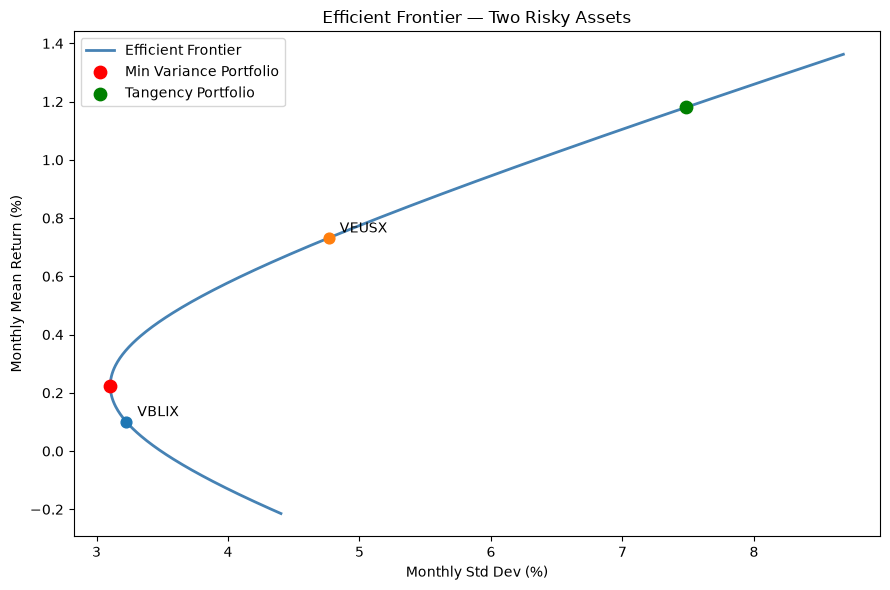

In [41]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(port_std * 100, port_ret * 100, color="steelblue", lw=2, label="Efficient Frontier")
#Min_var
ax.scatter(std_min_var * 100, ret_min_var * 100, color="red", zorder=5, s=80, label="Min Variance Portfolio")
#Tangency
ax.scatter(std_tangency * 100, ret_tangency * 100, color="green", zorder=5, s=80, label="Tangency Portfolio")

# Individual assets
for name, m, s in zip(["VBLIX", "VEUSX"], mu, np.sqrt(np.diag(cov))):
    ax.scatter(s * 100, m * 100, zorder=5, s=60)
    ax.annotate(name, (s * 100, m * 100), textcoords="offset points", xytext=(8, 4))

ax.set_xlabel("Monthly Std Dev (%)")
ax.set_ylabel("Monthly Mean Return (%)")
ax.set_title("Efficient Frontier — Two Risky Assets")
ax.legend()
plt.tight_layout()
plt.show()

## Part 2)

### 1) Data

In [42]:
### 1. Data
tickers2 = ["GOOG", "CSCO","LOGI", "AMZN","AAPL"]

raw2 = yf.download(tickers2, start="2015-01-01", auto_adjust=True)["Close"]

#Prices
prices_m2 = raw2.resample("ME").last().dropna()

#Normalized
prices_norm2 = prices_m2 / prices_m2.iloc[0] * 100

#Returns
ret_m2 = prices_m2.pct_change().dropna()

[*********************100%***********************]  5 of 5 completed


### 2) Individual metrics and Corr matrix

In [43]:
mu2  = ret_m2.mean()
cov2 = ret_m2.cov()
std2 = ret_m2.std()

In [44]:
rf = 0.00025

summary2 = pd.DataFrame({
    "Mean (monthly %)": mu2 * 100,
    "Std (monthly %)" : std2 * 100,
    "Sharpe (monthly)": (mu2 - rf) / std2
}, index=tickers2)

print(summary2.round(4))

      Mean (monthly %)  Std (monthly %)  Sharpe (monthly)
GOOG            2.0679           7.6373            0.2675
CSCO            1.4757           7.0758            0.2050
LOGI            2.0367           9.2694            0.2170
AMZN            2.2827           8.9638            0.2519
AAPL            2.1536           7.7451            0.2748


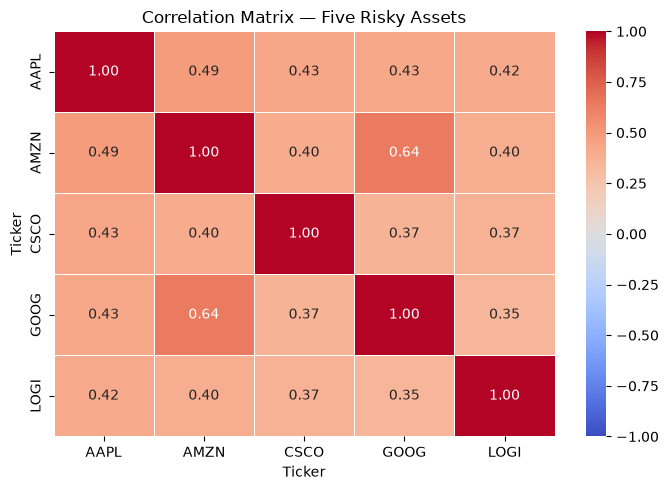

In [45]:
corr2 = ret_m2.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr2, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix — Five Risky Assets")
plt.tight_layout()
plt.savefig("corr_matrix_5assets.png", dpi=150)
plt.show()

### 3) Efficient frontier

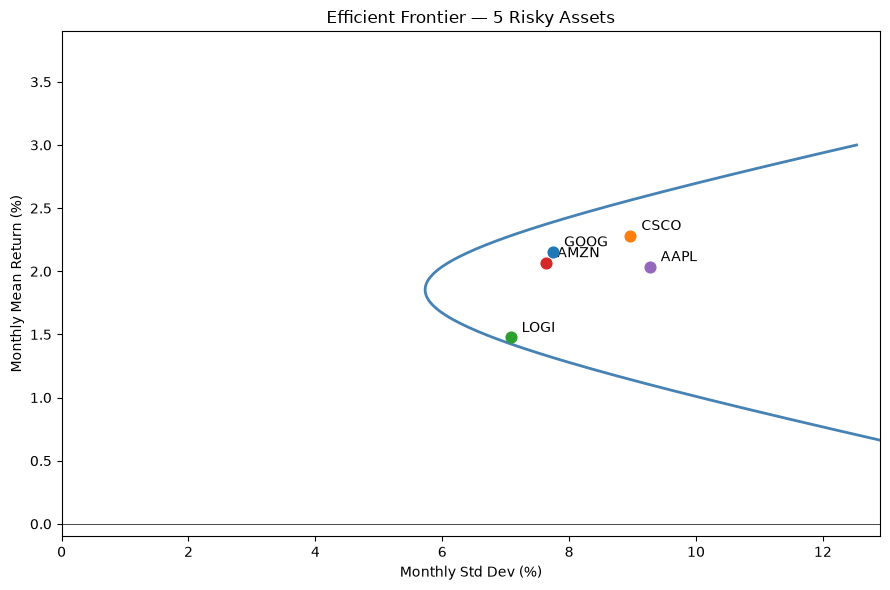

In [46]:
mu2  = ret_m2.mean().values
cov2 = ret_m2.cov().values
n    = len(mu2)

target_returns = np.linspace(0, 0.03, 300)  # ajuste selon tes mu
frontier_std   = []

for target in target_returns:
    constraints = [{"type": "eq", "fun": lambda w: w.sum() - 1},
                   {"type": "eq", "fun": lambda w, t=target: w @ mu2 - t}]
    result = minimize(lambda w: w @ cov2 @ w,
                      x0=np.ones(n)/n,
                      constraints=constraints,
                      method="SLSQP")
    frontier_std.append(np.sqrt(result.fun) if result.success else np.nan)

frontier_std = np.array(frontier_std)


#plot
plt.figure(figsize=(9, 6))
plt.plot(frontier_std * 100, target_returns * 100, color="steelblue", lw=2)

plt.axhline(y=0, color='black', linewidth=0.5)

for name, m, s in zip(tickers2, mu2, np.sqrt(np.diag(cov2))):
    plt.scatter(s * 100, m * 100, zorder=5, s=60)
    plt.annotate(name, (s * 100, m * 100), textcoords="offset points", xytext=(8, 4))

plt.xlim(0,12.9)
plt.ylim(-0.1,3.9)

plt.xlabel("Monthly Std Dev (%)")
plt.ylabel("Monthly Mean Return (%)")
plt.title("Efficient Frontier — 5 Risky Assets")
plt.tight_layout()
plt.show()

Tangency portfolio

In [47]:
excess_mu2 = mu2 - rf
inv_cov2   = np.linalg.inv(cov2)
ones2      = np.ones(n)

w_tan2_raw  = inv_cov2 @ excess_mu2
w_tan2      = w_tan2_raw / (ones2 @ w_tan2_raw)

ret_tan2    = w_tan2 @ mu2
std_tan2    = np.sqrt(w_tan2 @ cov2 @ w_tan2)
sharpe_tan2 = (ret_tan2 - rf) / std_tan2

print(f"Tangency weights : {dict(zip(tickers2, w_tan2.round(4)))}")
print(f"Tangency mean    : {ret_tan2*100:.4f}%")
print(f"Tangency std     : {std_tan2*100:.4f}%")
print(f"Sharpe           : {sharpe_tan2:.4f}")

Tangency weights : {'GOOG': np.float64(0.3301), 'CSCO': np.float64(0.0995), 'LOGI': np.float64(0.1196), 'AMZN': np.float64(0.3073), 'AAPL': np.float64(0.1435)}
Tangency mean    : 2.0423%
Tangency std     : 6.0086%
Sharpe           : 0.3357


Min_Var portfolio

In [48]:
constraints_gmvp = [{"type": "eq", "fun": lambda w: w.sum() - 1}]

result_gmvp = minimize(lambda w: w @ cov2 @ w,
                       x0=np.ones(n)/n,
                       constraints=constraints_gmvp,
                       method="SLSQP")

w_gmvp2     = result_gmvp.x
ret_gmvp2   = w_gmvp2 @ mu2
std_gmvp2   = np.sqrt(w_gmvp2 @ cov2 @ w_gmvp2)
sharpe_gmvp2 = (ret_gmvp2 - rf) / std_gmvp2

print(f"GMVP weights : {dict(zip(tickers2, w_gmvp2.round(4)))}")
print(f"GMVP mean    : {ret_gmvp2*100:.4f}%")
print(f"GMVP std     : {std_gmvp2*100:.4f}%")
print(f"GMVP Sharpe  : {sharpe_gmvp2:.4f}")

GMVP weights : {'GOOG': np.float64(0.2401), 'CSCO': np.float64(0.0082), 'LOGI': np.float64(0.397), 'AMZN': np.float64(0.247), 'AAPL': np.float64(0.1077)}
GMVP mean    : 1.8518%
GMVP std     : 5.7286%
GMVP Sharpe  : 0.3189


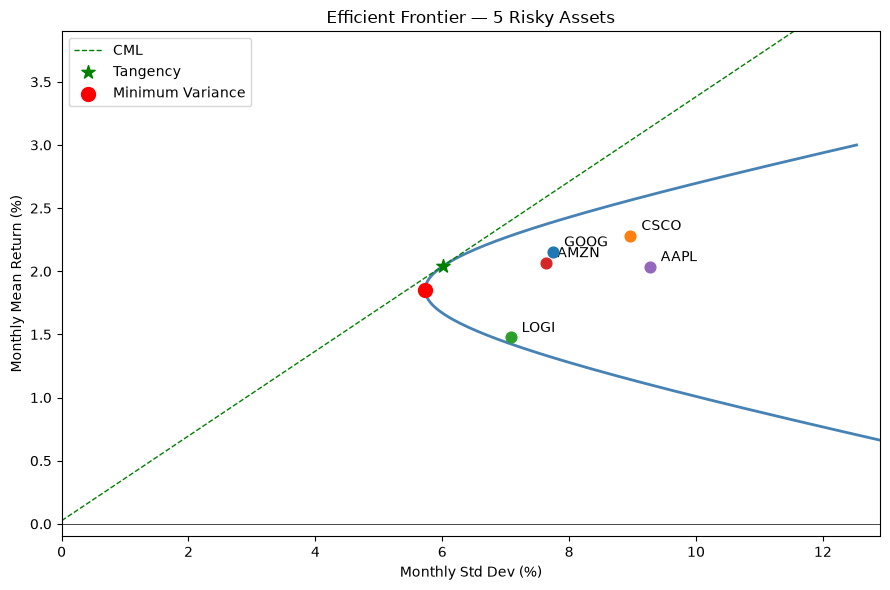

In [49]:
#CML
cml_x = np.linspace(0, std_tan2 * 2, 300)
cml_y = rf + sharpe_tan2 * cml_x


plt.figure(figsize=(9, 6))
plt.plot(frontier_std * 100, target_returns * 100, color="steelblue", lw=2)

plt.axhline(y=0, color='black', linewidth=0.)

for name, m, s in zip(tickers2, mu2, np.sqrt(np.diag(cov2))):
    plt.scatter(s * 100, m * 100, zorder=5, s=60)
    plt.annotate(name, (s * 100, m * 100), textcoords="offset points", xytext=(8, 4))

plt.plot(cml_x * 100, cml_y * 100, color="green", lw=1, linestyle="--", label="CML")
plt.scatter(std_tan2 * 100, ret_tan2 * 100, color="green", zorder=5, s=100, marker="*", label="Tangency")
plt.scatter(std_gmvp2 * 100, ret_gmvp2 * 100, color="red", zorder=5, s=100, label="Minimum Variance")

plt.xlabel("Monthly Std Dev (%)")
plt.ylabel("Monthly Mean Return (%)")
plt.title("Efficient Frontier — 5 Risky Assets")

plt.axhline(y=0, color='black', linewidth=0.5)

plt.xlim(0,12.9)
plt.ylim(-0.1,3.9)

plt.tight_layout()
plt.legend()
plt.show()


# Stock Market Q3.2

## 0. Data handling

In [50]:
def clean_datam(df, columns):
  df[0] = pd.to_datetime(df[0], format='%Y%m', errors='coerce')
  df = df.dropna()
  df.columns = columns
  df = df.set_index('Date')
  return df

In [51]:
df_30 = pd.read_csv('data/30_Industry_Portfolios.csv',
                    header=None,
                    skiprows=12,
                    nrows=1208-12)



In [52]:
df_30 =clean_datam(df_30, ['Date','Food', 'Beer','Smoke','Games','Books','Hshld','Clths','Hlth','Chems','Txtls','Cnstr','Steel','FabPr','ElcEq','Autos','Carry','Mines', 'Coal','Oil','Util','Telcm','Servs','BusEq','Paper','Trans','Whlsl','Rtail','Meals','Fin','Other'])

In [53]:
df_factors = pd.read_csv('data/F-F_Research_Data_Factors.csv',
                             header=None,
                             skiprows=5,  #Skip header
                             nrows=1201-5)

In [54]:
df_factors = clean_datam(df_factors, ['Date','Mkt-RF','SMB','HML','RF'])

## 1.

In [55]:
rolling_returns = df_30.rolling(window=12).mean().shift(1)
rolling_returns = rolling_returns['1927-07':]
ranks = rolling_returns.rank(axis=1)
mean_ranks = ranks.mean()

print("Lowest average rank:", mean_ranks.idxmin(), mean_ranks.min())
print("Highest average rank:", mean_ranks.idxmax(), mean_ranks.max())

Lowest average rank: Telcm 14.152027027027026
Highest average rank: BusEq 16.88597972972973


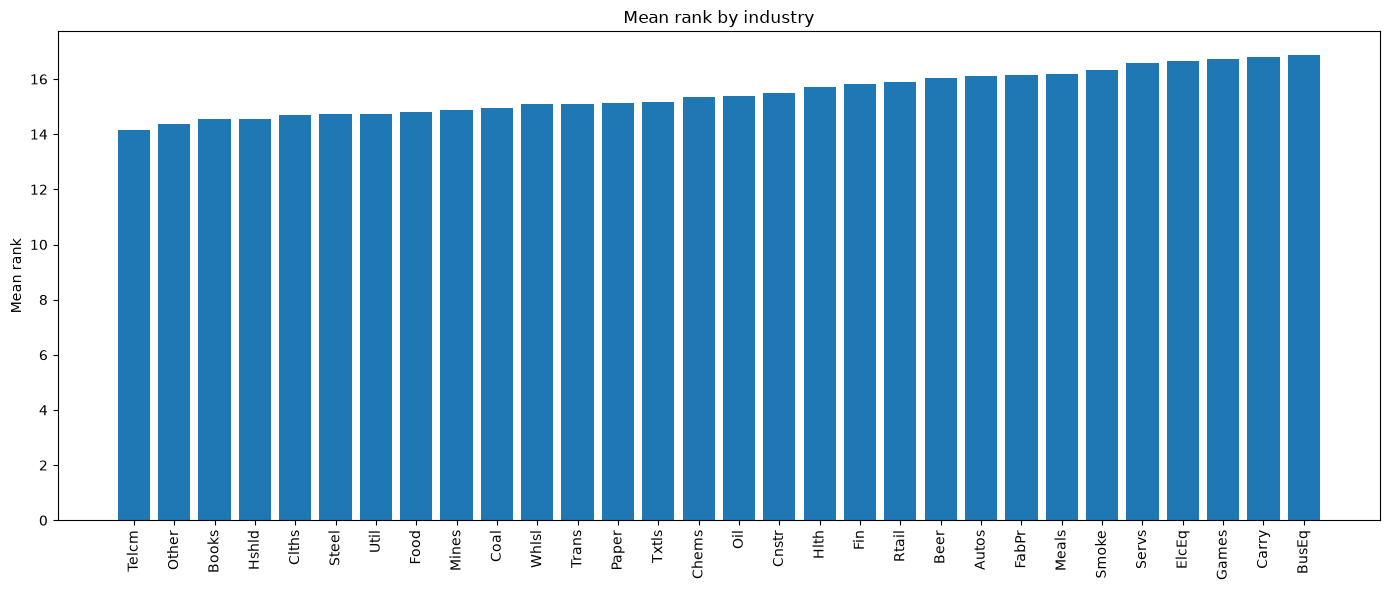

In [56]:
mean_ranks = ranks.mean().sort_values()

plt.figure(figsize=(14,6))
plt.bar(mean_ranks.index, mean_ranks.values)
plt.xticks(rotation=90)
plt.ylabel('Mean rank')
plt.title('Mean rank by industry')
plt.tight_layout()
plt.show()

In [57]:
mean_ranks.head

<bound method NDFrame.head of Telcm    14.152027
Other    14.358953
Books    14.543074
Hshld    14.548986
Clths    14.687922
Steel    14.742399
Util     14.743243
Food     14.805743
Mines    14.864443
Coal     14.967905
Whlsl    15.086149
Trans    15.086149
Paper    15.140625
Txtls    15.165541
Chems    15.340372
Oil      15.390203
Cnstr    15.491132
Hlth     15.693834
Fin      15.813345
Rtail    15.910051
Beer     16.025338
Autos    16.116976
FabPr    16.144848
Meals    16.180321
Smoke    16.311655
Servs    16.592905
ElcEq    16.665541
Games    16.733530
Carry    16.810811
BusEq    16.885980
dtype: float64>

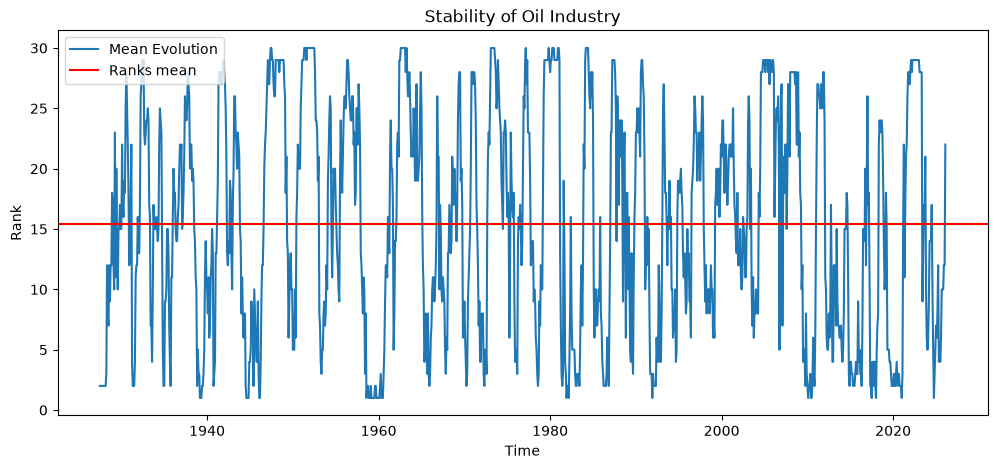

In [58]:
plt.figure(figsize=(12,5))
plt.plot(ranks['Oil'], label='Mean Evolution')
plt.axhline(ranks['Oil'].mean(), color = 'r', label='Ranks mean')
plt.title("Stability of Oil Industry")
plt.xlabel('Time')
plt.ylabel('Rank')
plt.legend(loc="upper left")


In [59]:
rank_autocorr = ranks.corrwith(ranks.shift(1), axis=1)

print("Average rank autocorrelation:", rank_autocorr.mean())

Average rank autocorrelation: 0.9103344317490775


In [60]:
#Top 5 Turnover
top5 = ranks >= 26

# change from one month to another
top5_changes = (top5 != top5.shift(1)).sum(axis=1)

#mean turnover
avg_top5_turnover = (top5_changes / 5).mean()

print("Average top-5 turnover:", avg_top5_turnover)

Average top-5 turnover: 0.4489864864864865


## 2. Winner portfolio

In [61]:
#Id winners
winners = (ranks > 15).astype(int)
#creates weights
winner_weights = winners.div(winners.sum(axis=1), axis=0)
#Returns
winner_ret = (winner_weights * df_30.loc[winner_weights.index]).sum(axis=1)


In [62]:
print("Index matches:", winner_weights.index.equals(df_30.loc[winner_weights.index].index))


Index matches: True


In [63]:
#Risk free
df_factors['RF'].mean()

np.float64(0.270066889632107)

In [64]:
winner_excess_rets = winner_ret - df_factors['RF']
print("Winner excess mean:", winner_excess_rets.mean())
print("Winner excess std:",winner_excess_rets.std())

Winner excess mean: 0.964236451295045
Winner excess std: 5.5618922256745265


In [65]:
winner_sharpe_monthly = winner_excess_rets.mean() / winner_excess_rets.std()
winner_sharpe_annualized = winner_sharpe_monthly * np.sqrt(12)

print(f"Monthly Sharpe Ratio: {winner_sharpe_monthly:.4f}")
print(f"Annualized Sharpe Ratio: {winner_sharpe_annualized:.4f}")



Monthly Sharpe Ratio: 0.1734
Annualized Sharpe Ratio: 0.6006


## 3. Looser Portfolio

In [66]:
#Id loosers
loosers = (ranks < 15).astype(int)
#creates weights
looser_weights = loosers.div(loosers.sum(axis=1), axis=0)
#Returns
looser_ret = (looser_weights * df_30.loc[looser_weights.index]).sum(axis=1)


In [67]:
print("Index matches:", looser_weights.index.equals(df_30.loc[looser_weights.index].index))


Index matches: True


In [68]:
looser_excess_rets = looser_ret - df_factors['RF']

print("Looser excess mean:", looser_excess_rets.mean())
print("Looser excess std:",looser_excess_rets.std())

Looser excess mean: 0.5170101351351352
Looser excess std: 6.0013552732679045


In [69]:
looser_sharpe_monthly = looser_excess_rets.mean() / looser_excess_rets.std()
looser_sharpe_annualized = looser_sharpe_monthly * np.sqrt(12)

print(f"Monthly Sharpe Ratio: {looser_sharpe_monthly:.4f}")
print(f"Annualized Sharpe Ratio: {looser_sharpe_annualized:.4f}")



Monthly Sharpe Ratio: 0.0861
Annualized Sharpe Ratio: 0.2984


### Market returns and sharpe

In [70]:
market_ret = df_factors['Mkt-RF']['1927-07':]

market_excess_rets = market_ret + df_factors['RF']['1927-07':]

market_sharpe_monthly = market_excess_rets.mean() / market_excess_rets.std()
market_sharpe_annualized = market_sharpe_monthly * np.sqrt(12)

print(f"Monthly Sharpe Ratio: {market_sharpe_monthly:.4f}")
print(f"Annualized Sharpe Ratio: {market_sharpe_annualized:.4f}")


Monthly Sharpe Ratio: 0.1796
Annualized Sharpe Ratio: 0.6220


## 4. Cumulative return

In [71]:
longshort_rets = winner_ret - looser_ret

In [72]:
def compute_cumulative(returns):
    # Produit cumulé : (1 + r1) * (1 + r2) * ...
    return (1 + returns/100).cumprod()

In [73]:
winner_cumulative_ret = compute_cumulative(winner_ret)
looser_cumulative_ret = compute_cumulative(looser_ret)
market_cumulative_ret = compute_cumulative(market_ret)
longshort_cumulative_ret = compute_cumulative(longshort_rets)

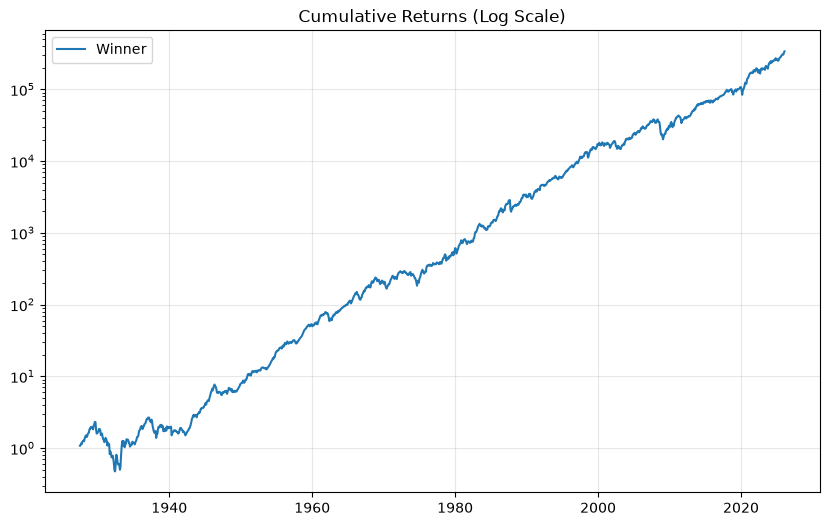

In [74]:
plt.figure(figsize=(10, 6))
plt.plot(winner_cumulative_ret, label='Winner')
plt.yscale('log')
plt.title('Cumulative Returns (Log Scale)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

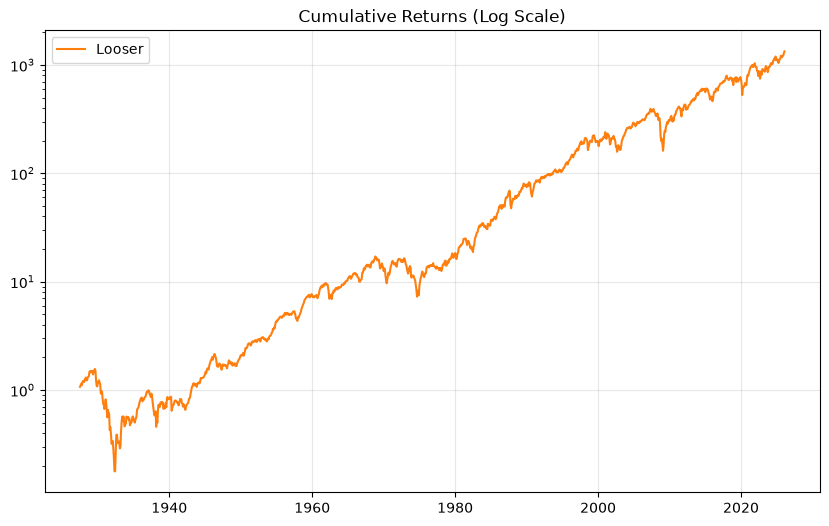

In [75]:
plt.figure(figsize=(10, 6))
plt.plot(looser_cumulative_ret, label='Looser', color='C1')
plt.yscale('log')
plt.title('Cumulative Returns (Log Scale)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

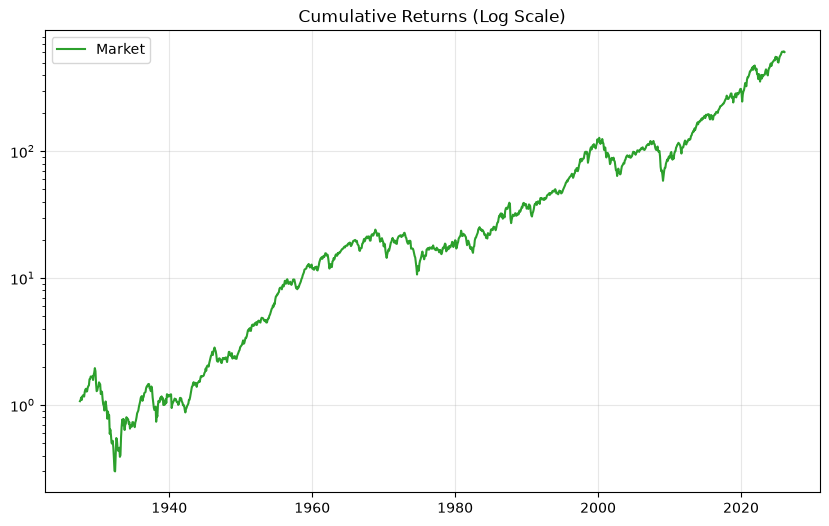

In [76]:
plt.figure(figsize=(10, 6))
plt.plot(market_cumulative_ret, label='Market',color='C2')
plt.yscale('log')
plt.title('Cumulative Returns (Log Scale)')
plt.legend()

plt.grid(alpha=0.3)
plt.show()

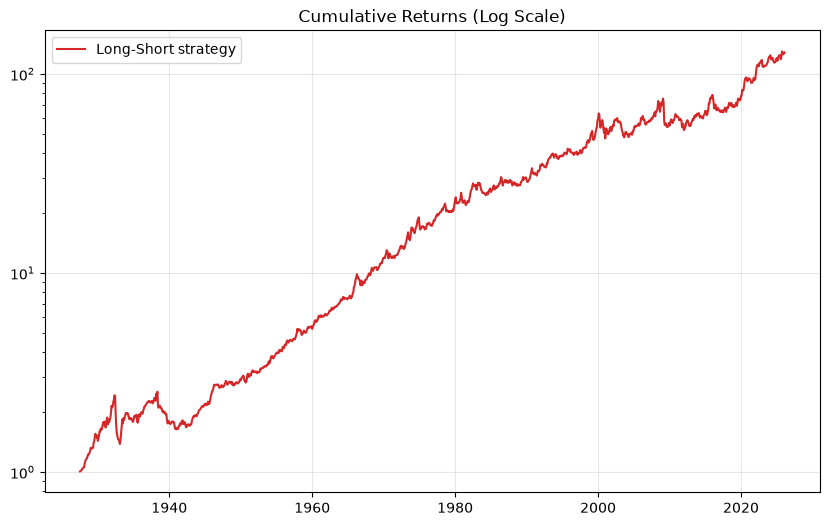

In [77]:
plt.figure(figsize=(10, 6))
plt.plot(longshort_cumulative_ret, label='Long-Short strategy',color='C3')
plt.yscale('log')
plt.title('Cumulative Returns (Log Scale)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

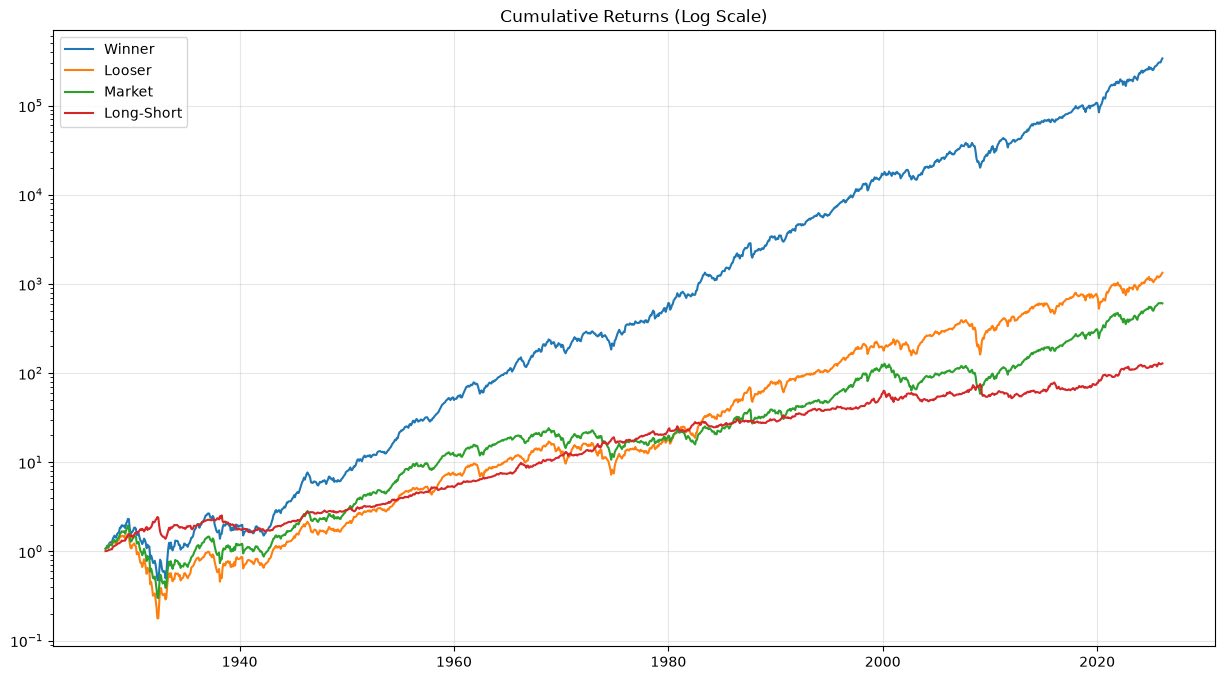

In [78]:
plt.figure(figsize=(15, 8))
plt.plot(winner_cumulative_ret, label='Winner')
plt.plot(looser_cumulative_ret, label='Looser')
plt.plot(market_cumulative_ret, label='Market')
plt.plot(longshort_cumulative_ret, label='Long-Short')

plt.yscale('log')
plt.title('Cumulative Returns (Log Scale)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. Ind-mom Loss

In [79]:
def plot_zoom_crash(cumulative_series, start_date, end_date, title="Zoom on Period"):
    zoom = cumulative_series.loc[start_date:end_date]
    if zoom.empty:
        print("Période vide, vérifie tes dates.")
        return

    norm = zoom / zoom.iloc[0]

    # Plot
    plt.figure(figsize=(10, 5))
    plt.plot(norm.index, norm, linewidth=2, color='C3')

    plt.title(f"{title} ({start_date} to {end_date})")
    plt.ylabel("Performance relative (Base 1)")
    plt.axhline(1, color='black', linewidth=0.5, linestyle='--')
    plt.grid(alpha=0.3)


    plt.tight_layout()
    plt.show()

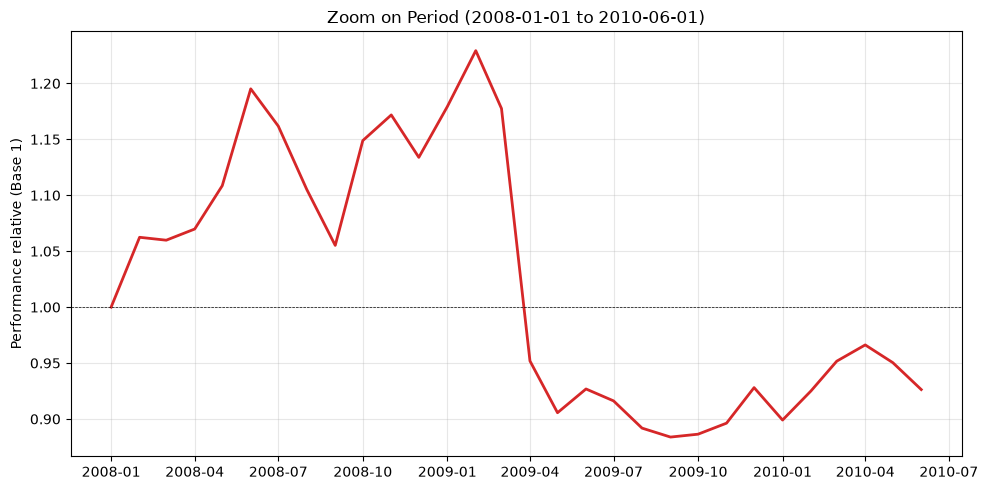

In [80]:
plot_zoom_crash(longshort_cumulative_ret, '2008-01-01', '2010-06-01', title="Zoom on Period")

In [81]:
print(longshort_rets['2009-03-01':'2009-05-01'])
print(winner_ret['2009-03-01':'2009-05-01'])
print(looser_ret['2009-03-01':'2009-05-01'])


Date
2009-03-01    -4.208000
2009-04-01   -19.164238
2009-05-01    -4.859667
dtype: float64
Date
2009-03-01    7.482000
2009-04-01    7.589333
2009-05-01    3.315333
dtype: float64
Date
2009-03-01    11.690000
2009-04-01    26.753571
2009-05-01     8.175000
dtype: float64


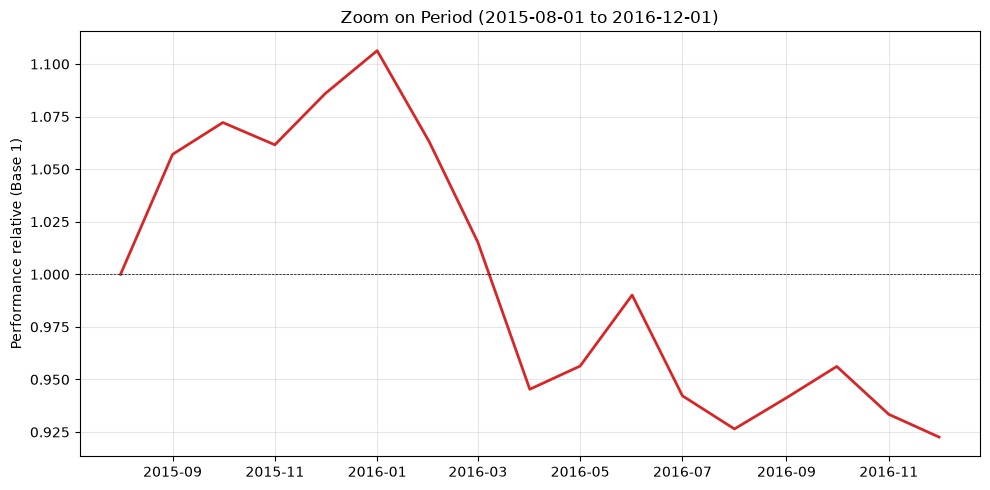

In [82]:
plot_zoom_crash(longshort_cumulative_ret, '2015-08-01', '2016-12-01', title="Zoom on Period")

In [83]:
print(longshort_rets['2016-02-01':'2016-04-01'])
print(winner_ret['2016-02-01':'2016-04-01'])
print(looser_ret['2016-02-01':'2016-04-01'])

Date
2016-02-01   -3.908429
2016-03-01   -4.496952
2016-04-01   -6.890476
dtype: float64
Date
2016-02-01    0.328000
2016-03-01    6.047333
2016-04-01   -0.613333
dtype: float64
Date
2016-02-01     4.236429
2016-03-01    10.544286
2016-04-01     6.277143
dtype: float64


# Bond market 4.1

## Data import

In [84]:
df = pd.read_csv('data/LW_monthly.csv', skiprows=8)  # Skip headers
df.columns = [col.strip() for col in df.columns]  # Clean
df['date'] = pd.to_datetime(df.iloc[:,0].astype(str), format='%Y%m')
df.set_index('date', inplace=True)
df = df.iloc[:,1:].astype(float)  # Yields float

/var/folders/lc/5629m9_j0qv09m42l0cy4hd40000gn/T/ipykernel_9516/2885286878.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['date'] = pd.to_datetime(df.iloc[:,0].astype(str), format='%Y%m')


## 4.1 test of long yield changes over the life of the short bond

### Test for 1 variable

In [85]:
# n = 12 (1 yr)
n = 12
col_n = '12 m'
col_n_minus_1 = '11 m'
col_1 = '1 m'

# dependent Variable : y_{t+1}^{(n-1)} - y_t^{(n)}
# décalle n-1 de 1 mois
delta_y = df[col_n_minus_1].shift(-1) - df[col_n]

# explicative Variable = (1/(n-1)) * (y_t^{(n)} - y_t^{(1)})
spread_adj = (df[col_n] - df[col_1]) / (n - 1)

# cleaning
data = pd.concat([delta_y, spread_adj], axis=1).dropna()
data.columns = ['delta_y', 'spread_adj']

In [86]:
X = sm.add_constant(data['spread_adj'])
model = sm.OLS(data['delta_y'], X).fit(
    cov_type='HAC',
    cov_kwds={'maxlags': 12}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                delta_y   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                  0.005
Method:                 Least Squares   F-statistic:                     1.471
Date:                Fri, 23 Oct 2026   Prob (F-statistic):              0.226
Time:                        14:34:55   Log-Likelihood:                -444.91
No. Observations:                 774   AIC:                             893.8
Df Residuals:                     772   BIC:                             903.1
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0102      0.025      0.405      0.6

In [87]:
mats = [3,6,9,12,24,36,48,60,120]
results = []

for n in mats:
    col_n = f'{n} m'
    col_n1 = f'{n-1} m'
    col_1 = '1 m'

    if col_n not in df.columns or col_n1 not in df.columns or col_1 not in df.columns:
        continue

    tmp = df[[col_n, col_n1, col_1]].dropna()
    tmp['delta_y'] = tmp[col_n1].shift(-1) - tmp[col_n]
    tmp['spread_adj'] = (tmp[col_n] - tmp[col_1]) / (n - 1)
    data = tmp[['delta_y', 'spread_adj']].dropna()

    X = sm.add_constant(data['spread_adj'])
    model = sm.OLS(data['delta_y'], X).fit(cov_type='HAC', cov_kwds={'maxlags':12})

    # Noms des paramètres au lieu des indices
    beta1 = model.params['spread_adj']
    se_beta1 = model.bse['spread_adj']
    t_beta1_1 = (beta1 - 1) / se_beta1

    results.append({
        'n': n,
        'beta1': beta1,
        'se': se_beta1,
        't(beta1=1)': t_beta1_1,
        'R2': model.rsquared,
        'obs': len(data)
    })

pd.DataFrame(results)

,n,beta1,se,t(beta1=1),R2,obs
0,3,-0.075251,0.569052,-1.889549,0.000123,774
1,6,-0.498859,0.583195,-2.570080,0.004264,774
2,9,-0.665236,0.610375,-2.728216,0.005752,774
3,12,-0.761966,0.628261,-2.804512,0.006070,774
4,24,-1.053437,0.694459,-2.956886,0.006873,774
5,36,-1.410894,0.761909,-3.164280,0.008942,774
6,48,-1.753817,0.798328,-3.449483,0.010752,774
7,60,-1.909555,0.839536,-3.465670,0.010524,774
8,120,-3.149518,1.004511,-4.130884,0.015285,652


### Test multivariate

In [88]:
results = []
mats_n = [2, 3, 4, 6, 9, 12, 24, 36, 48, 60, 120]
mats_m = [1, 2, 3, 4, 6, 12, 24, 60]

for n in mats_n:
    row = {'n': n}
    for m in mats_m:
        if m >= n: continue # m < n

        col_n = f'{n} m'
        col_n_minus_m = f'{n-m} m'
        col_m = f'{m} m'

        # Test : y(n-m, t+m) - y(n, t) = ...
        delta_y = df[col_n_minus_m].shift(-m) - df[col_n]
        spread_adj = (df[col_n] - df[col_m]) / (n - m)

        data = pd.concat([delta_y, spread_adj], axis=1).dropna()

        X = sm.add_constant(data[1]) # spread_adj
        model = sm.OLS(data[0], X).fit(cov_type='HAC', cov_kwds={'maxlags': 12})

        # format of beta (se)
        row[f'{m} m'] = f"{model.params[1]:.4f}\n({model.bse[1]:.4f})"

    results.append(row)

final_df = pd.DataFrame(results).set_index('n')
print(final_df)

                   1 m                2 m                3 m  \
n                                                              
2     0.1679\n(0.5744)                NaN                NaN   
3    -0.0753\n(0.5691)  -0.6086\n(0.9574)                NaN   
4    -0.2650\n(0.5692)  -0.8341\n(0.9719)  -0.7710\n(1.2548)   
6    -0.4989\n(0.5832)  -1.1722\n(1.0138)  -1.2972\n(1.3072)   
9    -0.6652\n(0.6104)  -1.5457\n(1.0825)  -1.8912\n(1.4255)   
12   -0.7620\n(0.6283)  -1.8599\n(1.1315)  -2.3875\n(1.5286)   
24   -1.0534\n(0.6945)  -2.4132\n(1.2504)  -3.1889\n(1.7119)   
36   -1.4109\n(0.7619)  -3.0018\n(1.3868)  -4.0347\n(1.8916)   
48   -1.7538\n(0.7983)  -3.6150\n(1.4618)  -4.8459\n(1.9907)   
60   -1.9096\n(0.8395)  -3.8892\n(1.5149)  -5.1639\n(2.0568)   
120  -3.1495\n(1.0045)  -6.0928\n(1.8730)  -8.0180\n(2.5308)   

                   4 m                 6 m                12 m  \
n                                                                
2                  NaN             

## 4.2 test of short yield changes over the life of the long bond

In [89]:
results_comp = []
mats_n = [2, 3, 4, 6, 9, 12, 24, 36, 48, 60, 120]

for n in mats_n:
    m = 1
    col_n = f'{n} m'
    col_m = '1 m'
    if col_n not in df.columns or col_m not in df.columns:
        continue

    dep = sum(df[col_m].shift(-i) for i in range(1, n - m + 1)) / (n - m) - df[col_m]
    spread = (df[col_n] - df[col_m]) / (n - m)

    data = pd.concat([dep.rename('y'), spread.rename('x')], axis=1).dropna()
    if len(data) < 20:
        continue

    X = sm.add_constant(data['x'])
    model = sm.OLS(data['y'], X).fit(cov_type='HAC', cov_kwds={'maxlags': 12})

    results_comp.append({
        'n': n,
        'beta0': model.params['const'],
        'beta1': model.params['x'],
        'se_beta1': model.bse['x'],
        't(beta1=1)': (model.params['x'] - 1) / model.bse['x'],
        'R2': model.rsquared,
        'obs': int(model.nobs)
    })

comp_df = pd.DataFrame(results_comp).set_index('n')
print(comp_df)

        beta0      beta1   se_beta1  t(beta1=1)        R2  obs
n                                                             
2   -0.075368   1.167869   0.574408    0.292246  0.029459  774
3   -0.079238   1.280711   0.749427    0.374567  0.024356  773
4   -0.095933   1.618677   0.925572    0.668427  0.028013  772
6   -0.130347   2.443133   1.217922    1.184914  0.036335  770
9   -0.171443   3.799688   1.732951    1.615561  0.046700  767
12  -0.221849   5.645125   2.282495    2.035108  0.062012  764
24  -0.367849  13.819118   5.028070    2.549511  0.084753  752
36  -0.535693  23.863536   8.381454    2.727872  0.106121  740
48  -0.703073  33.674209  10.555275    3.095534  0.127125  728
60  -0.873878  43.943657  12.300689    3.491159  0.158649  716
120 -1.908546  93.378600  22.329630    4.137041  0.227776  534


In [90]:
results2 = []
mats_n = [2, 3, 4, 6, 9, 12, 24, 36, 48, 60, 120]
mats_m = [1, 2, 3, 4, 6, 12, 24, 60]

for n in mats_n:
    row = {'n': n}
    for m in mats_m:
        if m >= n:
            continue

        col_n = f'{n} m'
        col_m = f'{m} m'

        if col_n not in df.columns or col_m not in df.columns:
            row[f'{m} m'] = ''
            continue

        dep = sum(df[col_m].shift(-i) for i in range(1, n - m + 1)) / (n - m) - df[col_m]
        x = (df[col_n] - df[col_m]) / (n - m)

        data = pd.concat([dep.rename('y'), x.rename('x')], axis=1).dropna()
        if len(data) < 20:
            row[f'{m} m'] = ''
            continue

        X = sm.add_constant(data['x'])
        model2 = sm.OLS(data['y'], X).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
        row[f'{m} m'] = f"{model2.params['x']:.4f}\n({model2.bse['x']:.4f})"

    results2.append(row)

final_df2 = pd.DataFrame(results2).set_index('n')
print(final_df2)

                    1 m                 2 m                 3 m  \
n                                                                 
2      1.1679\n(0.5744)                 NaN                 NaN   
3      1.2807\n(0.7494)    0.9277\n(0.5834)                 NaN   
4      1.6187\n(0.9256)    1.0692\n(0.7708)    0.7320\n(0.5945)   
6      2.4431\n(1.2179)    1.8307\n(1.0932)    1.2201\n(0.9704)   
9      3.7997\n(1.7330)    3.1373\n(1.5755)    2.5456\n(1.4322)   
12     5.6451\n(2.2825)    4.6922\n(2.0893)    3.8247\n(1.9234)   
24    13.8191\n(5.0281)   12.4639\n(4.8493)   11.0792\n(4.6517)   
36    23.8635\n(8.3815)   22.4656\n(8.3582)   20.9092\n(8.2956)   
48   33.6742\n(10.5553)  32.8848\n(10.4835)  32.0697\n(10.4209)   
60   43.9437\n(12.3007)  43.1356\n(12.2060)  42.2901\n(12.0931)   
120  93.3786\n(22.3296)  92.0641\n(22.4214)  90.5051\n(22.4811)   

                    4 m                 6 m                12 m  \
n                                                            